# Prerequisite 05 · 机器学习基础：训练不是背 API

[上一章：概率与采样](Prerequisite04B_Probability.ipynb) · [下一章：神经网络从零开始](Prerequisite05B_Neural_Network_From_Scratch.ipynb)

**目标：**理解模型、loss、优化、训练/验证/测试、过拟合和 baseline。RL 虽没有现成标签，但同样依赖这些训练原则。


## 1. 监督学习的最小闭环

给定输入 $x$ 和目标 $y$，模型产生 $\hat y=f_\theta(x)$，loss 衡量误差，梯度下降更新参数：

$$\theta\leftarrow\theta-\alpha\nabla_\theta L(\theta)$$

学习率 $\alpha$ 太小进展慢，太大会震荡或发散。RL 中 target 来自 reward 和 bootstrap，而不是人工标签，但优化器看到的仍是 loss。


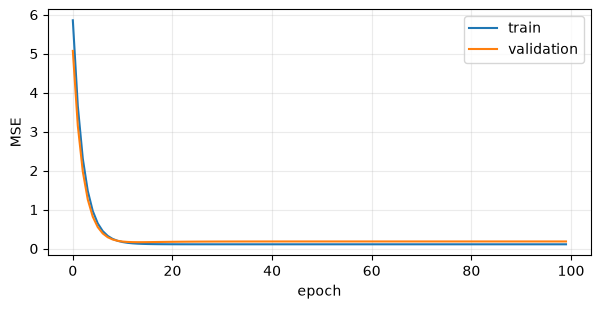

w/b: 2.542 -0.744 validation MSE: 0.183


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(5)
x = rng.uniform(-2, 2, 160)
y = 2.5*x - .7 + rng.normal(0, .35, len(x))
indices = rng.permutation(len(x))
train_idx, val_idx = indices[:120], indices[120:]
w, b, lr = 0.0, 0.0, .08
train_loss, val_loss = [], []
for _ in range(100):
    error = w*x[train_idx] + b - y[train_idx]
    w -= lr * 2*np.mean(error*x[train_idx])
    b -= lr * 2*np.mean(error)
    train_loss.append(np.mean((w*x[train_idx]+b-y[train_idx])**2))
    val_loss.append(np.mean((w*x[val_idx]+b-y[val_idx])**2))

plt.figure(figsize=(7, 3.2)); plt.plot(train_loss, label="train"); plt.plot(val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("w/b:", round(w, 3), round(b, 3), "validation MSE:", round(val_loss[-1], 3))


## 2. 为什么要分 train / validation / test

- **train：**更新参数。
- **validation：**选择模型和超参数。
- **test：**所有决定完成后，只用于一次最终评估。

在 test 上反复调参，相当于把 test 变成 validation。股票、文本世界和网页任务尤其容易因时间或相似样本泄漏而得到虚高结果。


## 3. 过拟合、归一化和 baseline

- 训练 loss 继续下降、validation loss 上升，是典型过拟合信号。
- 归一化统计量只能从训练数据估计，再应用到 validation/test。
- 更复杂模型必须和随机、规则或简单线性 baseline 比较。
- 公平比较要固定数据、预算、指标与随机种子集合。

RL 的训练分布会随策略变化，因此比监督学习更难；这些原则不是可以跳过，反而更重要。


In [2]:
# 同一个错误尺度下，比较三个学习率的梯度下降轨迹。
def optimize(lr, steps=25):
    value, history = 4.0, []
    for _ in range(steps):
        value -= lr * 2*value  # d(value^2)/dvalue = 2*value
        history.append(value**2)
    return history

for lr in (.02, .2, 1.1):
    history = optimize(lr)
    print(f"lr={lr}: first={history[0]:.3f}, last={history[-1]:.3f}")


lr=0.02: first=14.746, last=2.078
lr=0.2: first=5.760, last=0.000
lr=1.1: first=23.040, last=145607.010


## 4. 分类：从“预测一个数”到“预测概率”

回归输出任意实数；**分类**输出“属于每一类的概率”。最简单的分类模型是**逻辑回归**：

$$p(y=1\mid x)=\sigma(xw+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

损失用**交叉熵**：正确类别的概率越低，惩罚越大。RL 中的离散策略 $\pi(a\mid s)$ 就是一个“多分类器”：
输入状态，输出每个动作的概率——只是训练信号来自奖励，而不是标签。


w: [3.32  3.253] b: 0.02 训练准确率: 0.995


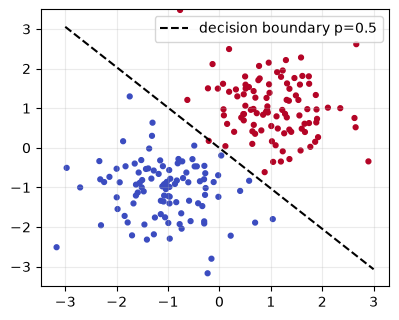

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
n = 200
x0 = rng.normal([-1.0, -1.0], 0.8, size=(n // 2, 2))
x1 = rng.normal([1.2, 1.0], 0.8, size=(n // 2, 2))
X = np.vstack([x0, x1]); y = np.r_[np.zeros(n // 2), np.ones(n // 2)]

w, b, lr = np.zeros(2), 0.0, 0.5
for _ in range(300):
    p = 1 / (1 + np.exp(-(X @ w + b)))
    w -= lr * X.T @ (p - y) / n          # 交叉熵对 w 的梯度
    b -= lr * np.mean(p - y)
accuracy = np.mean((p > 0.5) == y)
print("w:", np.round(w, 3), "b:", round(b, 3), "训练准确率:", accuracy)

xs = np.linspace(-3, 3, 50)
plt.figure(figsize=(4.5, 3.6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12)
plt.plot(xs, -(w[0] * xs + b) / w[1], "k--", label="decision boundary p=0.5")
plt.ylim(-3.5, 3.5); plt.legend(); plt.grid(alpha=.25); plt.show(); plt.close()


## 5. 亲眼看到过拟合

用不同复杂度的多项式拟合 15 个带噪点。阶数太低：**欠拟合**（训练、验证误差都高）；
阶数太高：**过拟合**（训练误差很低，验证误差变大）。在 RL 里，过拟合表现为“在训练用的随机种子或数据区间上很好，换一个就崩”。


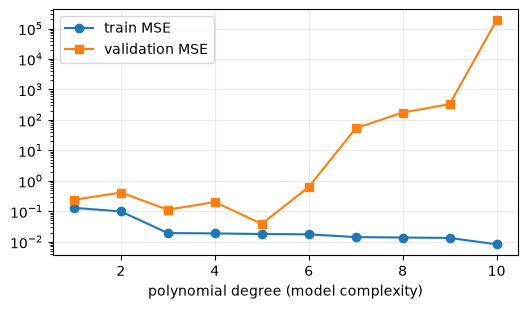

验证误差最小的阶数: 5  10 阶的训练/验证误差: 0.0082 187107.18


In [4]:
rng = np.random.default_rng(2)
x_tr = np.sort(rng.uniform(-1, 1, 15)); y_tr = np.sin(3 * x_tr) + rng.normal(0, .15, 15)
x_va = np.sort(rng.uniform(-1, 1, 100)); y_va = np.sin(3 * x_va) + rng.normal(0, .15, 100)

degrees = range(1, 11)
train_err, val_err = [], []
for d in degrees:
    coef = np.polyfit(x_tr, y_tr, d)
    train_err.append(np.mean((np.polyval(coef, x_tr) - y_tr) ** 2))
    val_err.append(np.mean((np.polyval(coef, x_va) - y_va) ** 2))

plt.figure(figsize=(6, 3.2))
plt.plot(list(degrees), train_err, "o-", label="train MSE"); plt.plot(list(degrees), val_err, "s-", label="validation MSE")
plt.yscale("log"); plt.xlabel("polynomial degree (model complexity)"); plt.legend(); plt.grid(alpha=.25); plt.show(); plt.close()
best = int(np.argmin(val_err)) + 1
print("验证误差最小的阶数:", best, " 10 阶的训练/验证误差:", round(train_err[-1], 4), round(val_err[-1], 2))


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [5]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：随机划分训练/验证索引

实现 `train_val_split(n, val_fraction, seed)`：返回 `(train_idx, val_idx)` 两个整数数组，二者不重叠、合起来正好是 `0..n-1`，验证集大小为 `int(n * val_fraction)`。

<details><summary>提示（卡住 10 分钟再看）</summary>

`perm = np.random.default_rng(seed).permutation(n)`，前面的给验证集，剩下的给训练集。

</details>


In [6]:
import numpy as np

def train_val_split(n, val_fraction, seed):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_train_val_split():
    tr, va = train_val_split(100, 0.2, seed=0)
    assert len(va) == 20 and len(tr) == 80, "验证集应 20 个、训练集 80 个"
    assert len(set(tr) & set(va)) == 0, "训练集与验证集不能重叠"
    assert sorted(np.r_[tr, va].tolist()) == list(range(100)), "合起来应覆盖全部索引"
    tr2, va2 = train_val_split(100, 0.2, seed=0)
    assert np.array_equal(va, va2), "相同 seed 应得到相同划分"

check(test_train_val_split)


[未完成] test_train_val_split：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def train_val_split(n, val_fraction, seed):
    perm = np.random.default_rng(seed).permutation(n)
    n_val = int(n * val_fraction)
    return perm[n_val:], perm[:n_val]
```

</details>


### 练习 2：一步梯度下降

对线性回归 $\hat y = xw+b$、损失 $L=\frac1N\sum(\hat y-y)^2$，实现 `gd_step(w, b, x, y, lr)`，返回更新后的 `(w, b)`。
梯度：$\partial L/\partial w=\frac2N\sum(\hat y-y)x$，$\partial L/\partial b=\frac2N\sum(\hat y-y)$。


In [7]:
import numpy as np

def gd_step(w, b, x, y, lr):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_gd_step():
    x = np.array([1.0, 2.0]); y = np.array([2.0, 4.0])
    w, b = gd_step(0.0, 0.0, x, y, lr=0.1)
    assert abs(w - 1.0) < 1e-9 and abs(b - 0.6) < 1e-9, f"一步后应为 w=1.0, b=0.6，得到 {w}, {b}"
    for _ in range(2000):
        w, b = gd_step(w, b, x, y, lr=0.1)
    assert abs(w - 2.0) < 1e-3 and abs(b) < 1e-3, "多步后应收敛到 w=2, b=0"

check(test_gd_step)


[未完成] test_gd_step：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def gd_step(w, b, x, y, lr):
    error = w * x + b - y
    return w - lr * 2 * np.mean(error * x), b - lr * 2 * np.mean(error)
```

</details>


### 练习 3：分类准确率

实现 `accuracy(probs, labels)`：`probs` 为 `(N,C)` 概率，`labels` 为 `(N,)` 整数类别，返回预测类别（概率最大者）等于标签的比例。


In [8]:
import numpy as np

def accuracy(probs, labels):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_accuracy():
    probs = np.array([[0.9, 0.1], [0.2, 0.8], [0.6, 0.4], [0.3, 0.7]])
    assert abs(accuracy(probs, [0, 1, 1, 1]) - 0.75) < 1e-9, "4 个里对了 3 个，应为 0.75"

check(test_accuracy)


[未完成] test_accuracy：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def accuracy(probs, labels):
    return float(np.mean(np.argmax(probs, axis=1) == np.asarray(labels)))
```

</details>


## 练习与过关标准

**练习：**解释为什么不能先对全部数据做标准化，再切分训练/测试；设计一个只比较学习率的公平实验。

**过关：**能解释 loss 与任务指标的区别；能正确划分数据；能识别过拟合和泄漏；知道一次只改变一个因素。

**选读：**[scikit-learn Getting Started](https://scikit-learn.org/stable/getting_started.html) 用于理解 fit/predict、预处理与模型评估；[Dive into Deep Learning 的线性模型部分](https://d2l.ai/chapter_linear-classification/)用于补充回归、分类和训练过程。
